In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.linear_model import LinearRegression
from scipy import stats
import torch
import torch.nn as nn
import torch.optim as optim
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('dark_background')
np.random.seed(42)
torch.manual_seed(42)

print("All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")

All libraries imported successfully!
PyTorch version: 2.11.0+cpu


In [4]:
# Load training and test data
train_df = pd.read_excel('/content/sample_data/train_data2.xlsx', engine='openpyxl')
test_df = pd.read_excel('/content/sample_data/test_data2.xlsx', engine='openpyxl')

# Separate features and target
X_train = train_df.drop('target', axis=1).values
y_train = train_df['target'].values
X_test = test_df.drop('target', axis=1).values
y_test = test_df['target'].values

print(f"Training data: {X_train.shape[0]} samples, {X_train.shape[1]} features")
print(f"Test data: {X_test.shape[0]} samples, {X_test.shape[1]} features")
print(f"\nClass distribution (train): {np.bincount(y_train)}")
print(f"Class distribution (test): {np.bincount(y_test)}")

Training data: 700 samples, 50 features
Test data: 300 samples, 50 features

Class distribution (train): [351 349]
Class distribution (test): [149 151]


In [9]:
from sklearn.preprocessing import StandardScaler

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fit baseline Gaussian Naive Bayes
gb_model = GaussianNB()
gb_model.fit(X_train_scaled, y_train)

# Predict probabilities
probas_gauss = gb_model.predict_proba(X_test_scaled)
test_auc_gauss = roc_auc_score(y_test, probas_gauss[:, 1])
test_acc_gauss = accuracy_score(y_test, gb_model.predict(X_test_scaled))

print("GAUSSIAN NAIVE BAYES (Baseline)")
print("="*50)
print(f"Test AUC: {test_auc_gauss:.4f}")
print(f"Test Accuracy: {test_acc_gauss:.4f}")

GAUSSIAN NAIVE BAYES (Baseline)
Test AUC: 1.0000
Test Accuracy: 1.0000


## Exercise 1: Naive Bayes with t-Distribution


In [10]:
def estimate_probability_t(x_value, data, df=5):
    """
    Estimate probability using t-distribution.
    """
    mean = np.mean(data)
    std = np.std(data) + 1e-9

    return stats.t.pdf(x_value, df=df, loc=mean, scale=std)


def naive_bayes_t_distribution(X_train, y_train, X_test, df=5):
    """
    Naive Bayes with t-distribution likelihood.
    """
    classes = np.unique(y_train)
    n_samples = X_test.shape[0]
    n_features = X_train.shape[1]
    n_classes = len(classes)

    class_data = {}
    priors = {}
    for c in classes:
        X_c = X_train[y_train == c]
        class_data[c] = X_c
        priors[c] = len(X_c) / len(y_train)

    log_probas = np.zeros((n_samples, n_classes))

    for i, x in enumerate(X_test):
        for j, c in enumerate(classes):
            log_posterior = np.log(priors[c] + 1e-9)
            for feature_idx in range(n_features):
                feature_value = x[feature_idx]
                feature_data = class_data[c][:, feature_idx]
                likelihood = estimate_probability_t(feature_value, feature_data, df=df)
                log_posterior += np.log(likelihood + 1e-9)
            log_probas[i, j] = log_posterior

    max_log_proba = np.max(log_probas, axis=1, keepdims=True)
    probas = np.exp(log_probas - max_log_proba)
    probas = probas / np.sum(probas, axis=1, keepdims=True)

    return probas

In [11]:
# Test your implementation
probas_t = naive_bayes_t_distribution(X_train_scaled, y_train, X_test_scaled, df=5)
test_auc_t = roc_auc_score(y_test, probas_t[:, 1])
test_acc_t = accuracy_score(y_test, np.argmax(probas_t, axis=1))

print("T-DISTRIBUTION NAIVE BAYES")
print("="*50)
print(f"Test AUC: {test_auc_t:.4f}")
print(f"Test Accuracy: {test_acc_t:.4f}")
print(f"\nComparison with Gaussian AUC: {test_auc_gauss:.4f}")

T-DISTRIBUTION NAIVE BAYES
Test AUC: 1.0000
Test Accuracy: 1.0000

Comparison with Gaussian AUC: 1.0000


##Exercise 2: Robust Regression on Different Data

In [14]:
class LinearModel(nn.Module):
    def __init__(self):
        super(LinearModel, self).__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)

# Create new synthetic data
np.random.seed(123)
n_samples_ex2 = 150

# True relationship: y = 0.5x + 10
X_ex2 = np.random.uniform(0, 20, n_samples_ex2)
y_ex2_clean = 0.5 * X_ex2 + 10 + np.random.normal(0, 1, n_samples_ex2)

# Add 15% outliers on the RIGHT side, going UP
n_outliers_ex2 = int(0.15 * n_samples_ex2)
right_mask = X_ex2 > 15
right_indices = np.where(right_mask)[0]
outlier_idx_ex2 = np.random.choice(right_indices, min(n_outliers_ex2, len(right_indices)), replace=False)
y_ex2 = y_ex2_clean.copy()
y_ex2[outlier_idx_ex2] += np.random.uniform(8, 12, len(outlier_idx_ex2))  # All go UP

lr_mse_ex2 = LinearRegression()
lr_mse_ex2.fit(X_ex2.reshape(-1, 1), y_ex2)
slope_mse_ex2 = lr_mse_ex2.coef_[0]
intercept_mse_ex2 = lr_mse_ex2.intercept_
X_ex2_torch = torch.tensor(X_ex2, dtype=torch.float32).reshape(-1, 1)
y_ex2_torch = torch.tensor(y_ex2, dtype=torch.float32).reshape(-1, 1)

model_laplace_ex2 = LinearModel()
criterion_l1_ex2 = nn.L1Loss()  # L1Loss = MAE (Laplace assumption)
optimizer_ex2 = optim.Adam(model_laplace_ex2.parameters(), lr=0.1)
for epoch in range(1000):
    optimizer_ex2.zero_grad()
    preds = model_laplace_ex2(X_ex2_torch)
    loss = criterion_l1_ex2(preds, y_ex2_torch)
    loss.backward()
    optimizer_ex2.step()

slope_laplace_ex2 = model_laplace_ex2.linear.weight.item()
intercept_laplace_ex2 = model_laplace_ex2.linear.bias.item()
print(f"True Line: y = 0.500x + 10.000")
print(f"MSE Line:  y = {slope_mse_ex2:.3f}x + {intercept_mse_ex2:.3f}")
print(f"MAE Line:  y = {slope_laplace_ex2:.3f}x + {intercept_laplace_ex2:.3f}")

True Line: y = 0.500x + 10.000
MSE Line:  y = 0.866x + 7.684
MAE Line:  y = 0.567x + 9.604


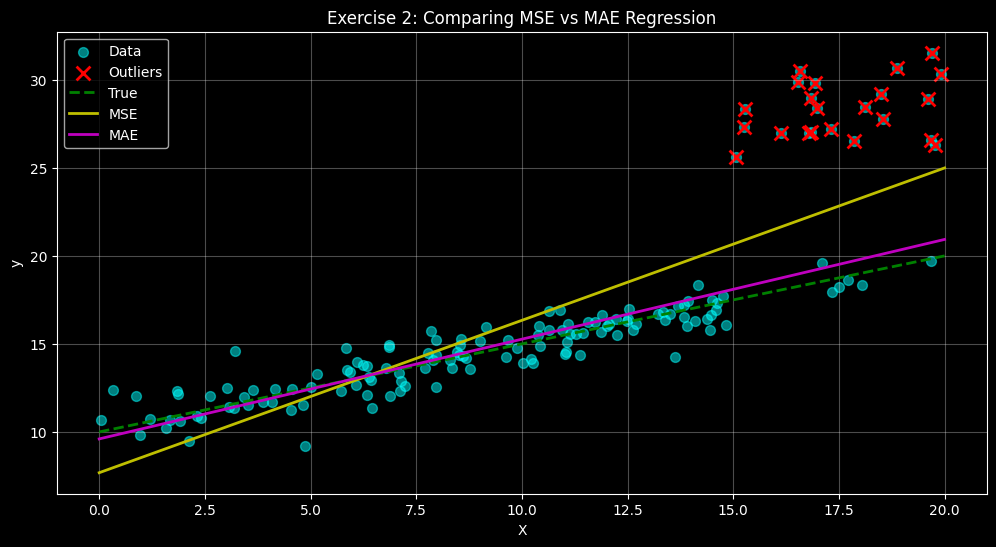

In [15]:
# Visualize your results
x_line_ex2 = np.linspace(0, 20, 100)

plt.figure(figsize=(12, 6))
plt.scatter(X_ex2, y_ex2, c='cyan', alpha=0.5, s=50, label='Data')
plt.scatter(X_ex2[outlier_idx_ex2], y_ex2[outlier_idx_ex2],
            c='red', s=100, marker='x', linewidth=2, label='Outliers')
plt.plot(x_line_ex2, 0.5 * x_line_ex2 + 10, 'g--', linewidth=2, label='True')
plt.plot(x_line_ex2, slope_mse_ex2 * x_line_ex2 + intercept_mse_ex2, 'y-', linewidth=2, label='MSE')
plt.plot(x_line_ex2, slope_laplace_ex2 * x_line_ex2 + intercept_laplace_ex2, 'm-', linewidth=2, label='MAE')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Exercise 2: Comparing MSE vs MAE Regression')
plt.legend()
plt.grid(alpha=0.3)
plt.show()